# Quociente de Rayleigh e o princípio min–max de Courant–Fischer

**Autor:** Tiago dos Santos Domingues - Professor Adjunto - DMA UFRJ

**Turma:** Álgebra Linear Avançada - 2026.2

**Licença**: esse material é coberto pela licença CC BY 4.0; que permite reuso com crédito.

**Disclaimer de uso de IA:** O material aqui apresentado teve o uso de IA na confecção de scripts e animações, e brainstorming com um agente de IA para definir escopo e exemplos.

Este notebook cobre o que veríamos na aula de quinta passada: ele revisa a construção variacional dos autovalores pelo quociente de Rayleigh e generaliza o resultado da aula anterior. Você pode mexer nos parametros das células de código.

**Roteiro.**

| Parte | Seções |
|---|---|
| **Parte I** — quociente de Rayleigh | §1 hipóteses · §2 existência de máximo e mínimo · §3 Lagrange: extremos são autovetores · §4 deflação e o teorema espectral |
| **Parte II** — Courant–Fischer | §5 motivação · §6 enunciado · §7 geometria em $\mathbb{R}^3$ · §8 demonstração · §9 consequências (Weyl, entrelaçamento) |
| **Exercícios** | §10, com soluções escondidas |

**Convenções** (as mesmas da Lista de Revisão de Teoria Espectral):

* o produto interno é linear na **segunda** entrada e conjugado-linear na primeira; em coordenadas ortonormais, $\langle x,y\rangle=\sum_i\overline{x_i}\,y_i=x^*y$;
* os autovalores de um operador autoadjunto são listados em ordem **decrescente**: $\lambda_1\ge\lambda_2\ge\cdots\ge\lambda_n$, repetidos conforme a multiplicidade.

**Como executar.** Em Jupyter local ou no Google Colab: mantenha a pasta `videos/` ao lado do notebook e execute a célula abaixo antes das demais. Só são usados `numpy`, `matplotlib` e (opcionalmente) `ipywidgets`.

In [2]:
# Configuração: execute esta célula primeiro.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Video, display

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

PASTA_VIDEOS = Path("videos")

def mostrar_video(nome, largura=720):
    caminho = PASTA_VIDEOS / f"{nome}.mp4"
    if caminho.exists():
        display(Video(str(caminho), embed=True, width=largura,
                      html_attributes="controls loop"))
    else:
        print(f"Vídeo {caminho} não encontrado: coloque a pasta 'videos/' ao lado do notebook.")

def rayleigh(A, x):
    # Quociente de Rayleigh R(x) = <x, Ax> / <x, x>  (np.vdot conjuga o 1º argumento).
    return np.real(np.vdot(x, A @ x) / np.vdot(x, x))

def hermitiana_aleatoria(n, complexa=False):
    M = rng.standard_normal((n, n))
    if complexa:
        M = M + 1j * rng.standard_normal((n, n))
    return (M + M.conj().T) / 2

def com_autovalores(lams):
    # Matriz real simétrica Q diag(lams) Q^T com Q ortogonal aleatória.
    Q, _ = np.linalg.qr(rng.standard_normal((len(lams), len(lams))))
    return Q @ np.diag(lams) @ Q.T

# Exemplo 2D dos vídeos.
A2 = np.array([[2.0, 1.0], [1.0, 2.0]])

# Exemplo 3D dos vídeos: A3 = Q diag(3, 2, 1) Q^T.
def _rot(eixo, ang):
    e = np.asarray(eixo, float); e = e / np.linalg.norm(e)
    K = np.array([[0, -e[2], e[1]], [e[2], 0, -e[0]], [-e[1], e[0], 0]])
    return np.eye(3) + np.sin(ang) * K + (1 - np.cos(ang)) * K @ K

Q3 = _rot([0, 0, 1], 0.5) @ _rot([1, 0, 0], 0.6) @ _rot([0, 1, 0], 0.35)
A3 = Q3 @ np.diag([3.0, 2.0, 1.0]) @ Q3.T
v1, v2, v3 = Q3.T            # autovetores de A3 (autovalores 3, 2, 1)
print("A3 =\n", A3)

A3 =
 [[ 2.2269  0.6209 -0.6375]
 [ 0.6209  2.2941  0.0579]
 [-0.6375  0.0579  1.479 ]]


## 0. Autovetores e formas quadráticas

Um autovetor de $A$ é uma direção $u$ em que $Au$ é paralelo a $u$. No vídeo abaixo, $u$ percorre o círculo unitário e acompanhamos o número
$$R(u)=\langle u,Au\rangle .$$ Aqui vemos empiricamente o que queremos demonstrar: as direções em que $Au\parallel u$ são exatamente aquelas em que $R(u)$ atinge seu **máximo** ($3$) e seu **mínimo** ($1$); e o valor de $R$ ali é o autovalor correspondente.

Intuitivamente, o produto interno $\langle u,Au\rangle$ mede a norma do primeiro vetor, vezes a norma do segundo, vezes o cosseno do ângulo entre eles, e esse produto interno é limitado por cima por cauchy schwartz pelo produto das normas. Faz sentido supor então que, se as normas dos vetores não podem mudar (pois restringimos o vetor $u$ a ser unitário), então o produto interno só pode ser maximizado se o ângulo entre os vetores for 0, pois nesse caso cauchy schwartz se torna uma igualdade. Mas se o ângulo é zero, existe uma constante de proporcionalidade que os relaciona, isto é, $u\propto A u$.
Esse é o tema de todo o notebook: **autovalores de operadores autoadjuntos são valores ótimos de problemas de otimização**, e autovetores são onde esses ótimos são atingidos.

In [11]:
mostrar_video("ColdOpenScene")

---
# Parte I — O quociente de Rayleigh

## 1. Hipóteses e notação

Ao longo de todo o notebook:

* $U$ é um espaço vetorial de dimensão finita $n$ sobre um corpo $K$ **completo** — na prática, $K=\mathbb{R}$ ou $K=\mathbb{C}$ (pense em $\mathbb{C}$ se preferir; o caso real é idêntico);
* $U$ tem um produto interno $\langle\cdot,\cdot\rangle$, com norma $\|x\|=\sqrt{\langle x,x\rangle}$;
* $A:U\to U$ é linear e **autoadjunto**: $\langle Ax,y\rangle=\langle x,Ay\rangle$ para todos $x,y\in U$.

A **forma quadrática** $F_A(x)$ associada a $A$ e o **quociente de Rayleigh** $R_A(x)$ são definidos como
$$F_A(x)=\langle x,Ax\rangle,\qquad R_A(x)=\frac{\langle x,Ax\rangle}{\langle x,x\rangle}\quad(x\neq0).$$
Escreveremos $S=\{x\in U:\|x\|=1\}$ para a esfera unitária.

Para $c\in K$, $c\ne0$, temos $F_A(cx)=\langle cx,A(cx)\rangle=\bar c\,c\,\langle x,Ax\rangle=|c|^2F_A(x)$. Ao dividirmos pelo denominador em $R_A$, fazemos esse mesmo fator $|c|^2$ aparecer no denominador. Logo $R_A(cx)=R_A(x)$: o quociente só depende da *direção* de $x$, e em $S$ ele coincide com $F_A$. Estudar $R_A$ em $U\setminus\{0\}$ é o mesmo que estudar $F_A$ em $S$.

Agora, vamos re-introduzir lemas que mostramos em aula.

**Lema 1 ($F_A$ é real).** Se $A$ é autoadjunto, $F_A(x)\in\mathbb{R}$ para todo $x$.

*Demonstração.* $\overline{F_A(x)}=\overline{\langle x,Ax\rangle}=\langle Ax,x\rangle=\langle x,Ax\rangle=F_A(x)$, usando a simetria conjugada do produto interno e depois $A$ ser autoadjunta. $\square$

O Lema 1 é o que dá sentido à pergunta "qual o *maior* valor de $F_A$ em $S$?": nos complexos, não existe uma ordem canonica de maior/menor.

**Em coordenadas.** Fixada uma base ortonormal $e_1,\dots,e_n$ de $U$, escrevemos $x=\sum_i x_ie_i$ e $a_{ij}=\langle e_i,Ae_j\rangle$. Então
$$F_A(x)=\sum_{i,j}\overline{x_i}\,a_{ij}\,x_j=x^*Ax,\qquad \|x\|^2=\sum_i|x_i|^2,$$
e $A$ ser autoadjunto equivale a $a_{ji}=\overline{a_{ij}}$ (matriz hermitiana; no caso real, simétrica).

In [49]:
# Verificação numérica: F_A é real para A hermitiana, e R_A é invariante por escala.
A = hermitiana_aleatoria(4, complexa=True)
x = rng.standard_normal(4) + 1j * rng.standard_normal(4)
F = np.vdot(x, A @ x)
print("F_A(x) =", F, "  -> parte imaginária desprezível:", abs(F.imag) < 1e-12)

c = 2.7 - 1.3j
print("R_A(x)  =", rayleigh(A, x))
print("R_A(cx) =", rayleigh(A, c * x))

# Para contraste: sem a propriedade de A autoadjunta, F_A(x) é complexo em geral.
B = rng.standard_normal((4, 4)) + 1j * rng.standard_normal((4, 4))
print("matriz não hermitiana: F_B(x) =", np.vdot(x, B @ x))

F_A(x) = (4.122782195554354-4.440892098500626e-16j)   -> parte imaginária desprezível: True
R_A(x)  = 0.4443669554840394
R_A(cx) = 0.4443669554840395
matriz não hermitiana: F_B(x) = (3.7813030670923338+10.170372185840247j)


## 2. Existência de máximo e mínimo em $S$

**Lema 2 (limitação e continuidade).** Existe uma constante $\|A\|<\infty$ tal que, para todos $x,y\in U$,
$$|F_A(x)|\le\|A\|\,\|x\|^2,\qquad |F_A(x)-F_A(y)|\le\|A\|\,\bigl(\|x\|+\|y\|\bigr)\,\|x-y\| .$$
Em particular $F_A$ é contínua (lipschitziana em conjuntos limitados).

*Demonstração.* Seja $\|A\|=\sup_{\|x\|=1}\|Ax\|=\sup_{x\neq \vec{0}} \frac{\|A x\|}{\|x\|}$ a norma da transformação linear $A$. Como o sup é uma cota superior, ele é maior ou igual do que o valor do quociente para um $x$ específico, logo
$$ \|A\| \geq \frac{\|A x\|}{\|x\|} \Leftrightarrow \|A x\| \leq \|A\| \|x\|.$$
Agora, por Cauchy–Schwarz em $U$: $|F_A(x)|=|\langle x,Ax\rangle|\le\|x\|\,\|Ax\|\le\|A\|\,\|x\|^2$. Para a continuidade, some e subtraia $\langle y,Ax\rangle$:
$$F_A(x)-F_A(y)=\langle x-y,Ax\rangle+\langle y,A(x-y)\rangle,$$
e aplique Cauchy–Schwarz a cada termo: $|F_A(x)-F_A(y)|\le\|A\|\|x\|\|x-y\|+\|y\|\|A\|\|x-y\|$. $\square$

**Teorema 1 (existência dos extremos).** $F_A$ atinge máximo e mínimo em $S$: existem $v_{\max},v_{\min}\in S$ com
$$F_A(v_{\max})=M:=\sup_SF_A,\qquad F_A(v_{\min})=m:=\inf_SF_A .$$

*Demonstração.* 
Como visto em aula, a esfera unitária é compacta se e somente se estamos em dimensão finita, logo $S$  é um conjunto compacto. Pelo Lema 2, $F_A(S)\subset[-\|A\|,\|A\|]$ é um conjunto limitado de números reais, logo $M=\sup_SF_A$ existe (completude de $\mathbb{R}$ novamente). Pela definição de supremo, existe uma sequência $(x_k)$ em $S$ com $F_A(x_k)\to M$. Pelo Lema 3, $(x_k)$ tem uma subsequência $x_{k_j}\to v$, e $v\in S$ porque $S$ é fechada. Pela continuidade (Lema 2), $F_A(v)=\lim_jF_A(x_{k_j})=M$. Assim o supremo é um **máximo**, atingido em $v_{\max}:=v$. O argumento para o ínfimo é o mesmo. $\square$

(Isto é o teorema de Weierstrass — função contínua em compacto atinge máximo e mínimo). Vamos listar as hipóteses que utilizamos até agora:

| Hipótese | Onde foi usada |
|---|---|
| $A$ autoadjunto | $F_A$ real (Lema 1): faz sentido falar em máximo |
| dimensão finita | $\lVert A\rVert<\infty$ e compacidade de $S$ da esfera unitária para um corpo completo |
| $F_A$ contínua | a imagem de $F_A(S)$ é um subconjunto compacto da reta real, existência de sup e inf, teorema de Weierstrass. |

A célula abaixo sorteia muitos vetores unitários e mostra que os valores de $F_A$ ficam presos num intervalo $[m,M]$ — e, como veremos no §3, esses extremos são os autovalores extremos.

menor amostra = -2.1576   lambda_min = -2.3492
maior amostra = 3.4781   lambda_max = 3.6924


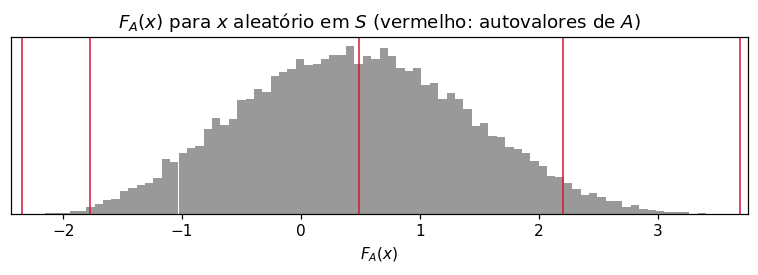

In [166]:
n = 5
A = hermitiana_aleatoria(n, complexa=True)
X = rng.standard_normal((20000, n)) + 1j * rng.standard_normal((20000, n))
X /= np.linalg.norm(X, axis=1, keepdims=True)              # pontos aleatórios em S
valores = np.real(np.einsum("ki,ij,kj->k", X.conj(), A, X))  # F_A(x) para cada x

lam = np.linalg.eigvalsh(A)          # só para comparação (ordem crescente)
print(f"menor amostra = {valores.min():.4f}   lambda_min = {lam[0]:.4f}")
print(f"maior amostra = {valores.max():.4f}   lambda_max = {lam[-1]:.4f}")

plt.figure(figsize=(7, 2.6))
plt.hist(valores, bins=80, color="0.6")
for l in lam:
    plt.axvline(l, color="crimson", lw=1)
plt.title(r"$F_A(x)$ para $x$ aleatório em $S$ (vermelho: autovalores de $A$)")
plt.xlabel(r"$F_A(x)$"); plt.yticks([]); plt.tight_layout(); plt.show()

Note que os extremos amostrados ficam *perto* de $\lambda_{\min}$ e $\lambda_{\max}$ sem atingi-los: amostragem aleatória em dimensão $5$ raramente cai perto do ponto ótimo. O Teorema 1 garante que o ótimo existe; o §3 diz onde ele está.

## 3. Multiplicadores de Lagrange: os extremos são autovetores

**Caso real.** Seja $K=\mathbb{R}$ e use coordenadas ortonormais, de modo que $a_{ij}=a_{ji}$. Queremos extremizar
$$f(x)=\sum_{i,j}x_i\,a_{ij}\,x_j\qquad\text{sujeito a}\qquad g(x)=\sum_ix_i^2-1=0 .$$
As derivadas parciais são
$$\frac{\partial f}{\partial x_k}=\sum_ja_{kj}x_j+\sum_ix_ia_{ik}=2\,(Ax)_k\quad(\text{simetria!}),\qquad \frac{\partial g}{\partial x_k}=2x_k,$$
isto é, $\nabla f(x)=2Ax$ e $\nabla g(x)=2x$. Como $\nabla g(x)=2x\neq0$ em todo ponto de $S$, a restrição é regular e o teorema dos multiplicadores de Lagrange se aplica: em todo ponto crítico $v$ de $f|_S$, existe $\mu\in\mathbb{R}$ com
$$\nabla f(v)=\mu\,\nabla g(v)\iff 2Av=2\mu v\iff Av=\mu v .$$ os autovetores são pontos críticos, e o valor da função $F_A(v)$ é o autovalor correspondente: $F_A(v)=\langle v,\mu v\rangle=\mu\|v\|^2=\mu$. 

**Caso complexo.** Escreva $x=a+ib$ e $A=B+iC$ com $a,b\in\mathbb{R}^n$ e $B,C$ reais. A condição $A^*=A$ significa $B^{\mathsf T}=B$ e $C^{\mathsf T}=-C$. Um cálculo direto (feito numericamente abaixo) mostra que
$$F_A(x)=\begin{pmatrix}a\\b\end{pmatrix}^{\!\mathsf T}\underbrace{\begin{pmatrix}B&-C\\C&B\end{pmatrix}}_{=:\,\widehat A}\begin{pmatrix}a\\b\end{pmatrix},\qquad \|x\|^2=\|a\|^2+\|b\|^2,$$
com $\widehat A$ real **simétrica** $2n\times2n$. Aplicando o caso real a $\widehat A$: num ponto crítico, $\widehat A\binom ab=\mu\binom ab$, isto é, $Ba-Cb=\mu a$ e $Ca+Bb=\mu b$ — que são exatamente as partes real e imaginária de $Ax=\mu x$.


Caso você não se recorde de onde vêm multiplicadores de Lagrange, assista o seguinte vídeo: https://www.youtube.com/watch?v=54EP7DSVWPE

**Teorema 2.** $M=\max_SF_A$ e $m=\min_SF_A$ são autovalores de $A$, com autovetores $v_{\max}$ e $v_{\min}$. Além disso, todo autovalor de $A$ está em $[m,M]$; portanto $M=\lambda_{\max}$ e $m=\lambda_{\min}$.

*Demonstração.* A primeira parte é o cálculo acima aplicado aos pontos dados pelo Teorema 1. Para a segunda: se $Ax=\lambda x$ com $\|x\|=1$, então $\lambda=\langle x,Ax\rangle=F_A(x)\in[m,M]$. $\square$

Vale também a recíproca do cálculo de Lagrange: se $Av=\lambda v$ com $v\in S$, então $\nabla f(v)=2\lambda v=\lambda\nabla g(v)$, e $v$ é ponto crítico de $f|_S$. O autovalor máximo e o mínimo são os pontos críticos máximo e mínimo, respectivamente; os autovetores intermediários são pontos de sela.

No vídeo abaixo, as curvas de nível da forma quadrática $\{F_A=c\}$ associada à matriz $A=\begin{pmatrix}2&1\\1&2\end{pmatrix}$ são elipses. Aumentando $c$, o **primeiro** contato com o círculo $S$ ocorre em $c=1=\min_SF_A$ (por dentro, em $\pm v_2$); a elipse então corta $S$ em quatro pontos, e o **último** contato ocorre em $c=3=\max_SF_A$ (por fora, em $\pm v_1$). Nos dois casos o contato é uma tangência: as normais $\nabla F_A$ e $\nabla g$ são paralelas — ou seja, $\nabla F_A(v)=\lambda\nabla g(v)$ (condição de Lagrange).

In [13]:
mostrar_video("LagrangeTangencyScene")

In [101]:
# 1) O truque do caso complexo: F_A(a + ib) = [a; b]^T Ahat [a; b].
n = 3
A = hermitiana_aleatoria(n, complexa=True)
B, C = A.real, A.imag
Ahat = np.block([[B, -C], [C, B]])
a, b = rng.standard_normal(n), rng.standard_normal(n)
x = a + 1j * b
print("F_A(x)            =", np.vdot(x, A @ x).real)
print("[a;b]^T Ahat [a;b] =", np.r_[a, b] @ Ahat @ np.r_[a, b])
print("Ahat simétrica?", np.allclose(Ahat, Ahat.T))

# 2) Pontos críticos = autovetores. O gradiente de R restrito à esfera
#    (projeção tangente de 2Ax) é 2(Ax - R(x)x); ele se anula exatamente nos autovetores.
def grad_tangente(A, x):
    return 2 * (A @ x - rayleigh(A, x) * x)

lam, V = np.linalg.eigh(A2)
for k in range(2):
    print(f"autovetor {V[:, k]}: R = {rayleigh(A2, V[:, k]):.3f}, "
          f"|grad tangente| = {np.linalg.norm(grad_tangente(A2, V[:, k])):.1e}")
u = np.array([1.0, 0.0])
print(f"vetor genérico {u}: R = {rayleigh(A2, u):.3f}, "
      f"|grad tangente| = {np.linalg.norm(grad_tangente(A2, u)):.2f}")

F_A(x)            = -3.2736886117494737
[a;b]^T Ahat [a;b] = -3.2736886117494737
Ahat simétrica? True
autovetor [-0.7071  0.7071]: R = 1.000, |grad tangente| = 0.0e+00
autovetor [0.7071 0.7071]: R = 3.000, |grad tangente| = 1.3e-15
vetor genérico [1. 0.]: R = 2.000, |grad tangente| = 2.00


## 4. Deflação: os demais autovetores e o teorema espectral

Até aqui temos dois autovetores, $v_{\max}$ e $v_{\min}$. A ideia agora é **retirá-los do espaço** e repetir o argumento no que sobra.

**Lema 4 (ortogonalidade).** Se $Av=\lambda v$ e $Aw=\mu w$ com $\lambda\neq\mu$, então $\langle v,w\rangle=0$.

*Demonstração.* Os autovalores são reais (pelo Teorema 2, $\lambda=F_A(v/\|v\|)$). Então
$\lambda\langle v,w\rangle=\langle\lambda v,w\rangle=\langle Av,w\rangle=\langle v,Aw\rangle=\mu\langle v,w\rangle$, logo $(\lambda-\mu)\langle v,w\rangle=0$. $\square$


**O caso degenerado $M=m$.** Se o máximo e o mínimo coincidem, $F_A$ é constante igual a $M$ em $S$, e *todo* $x\in S$ é ponto de máximo; pelo Teorema 2, todo $x\in S$ é autovetor com autovalor $M$, isto é, $A=M\cdot I$. Nesse caso qualquer base ortonormal é base de autovetores e não há mais nada a fazer. Daqui em diante suponha $M>m$; pelo Lema 4, $v_{\max}\perp v_{\min}$ e
$$H=\operatorname{span}\{v_{\max},v_{\min}\}$$
tem dimensão $2$.

**Lema 5 (invariância).** Se $H$ é gerado por autovetores de $A$, então $A(H)\subseteq H$ e $A(H^\perp)\subseteq H^\perp$.

*Demonstração.* A primeira inclusão é imediata. Para a segunda, seja $w\in H^\perp$ e $v\in H$ um dos autovetores geradores, $Av=\lambda v$ com $\lambda$ real. Então
$$\langle v,Aw\rangle=\langle Av,w\rangle=\lambda\langle v,w\rangle=0 .$$
Como $Aw$ é ortogonal a cada gerador de $H$, $Aw\in H^\perp$. $\square$

> **Atenção à ordem para evitar um argumento circular.** É tentador justificar a invariância dizendo "$H^\perp$ é gerado pelos autovetores restantes". Isso é possível se nós partimos da demonstração original do teorema espectral. Mas nesse caso, a iteração que estamos fazendo fornece uma demonstração alternativa e independente do teorema espectral para operadores autoadjuntos, que não necessita de determinantes e polinômios anuladores, nem da forma triangular de schur. Se estamos fazendo uma demonstração independente, **ainda não mostramos** que existem outros autovetores — nós iremos obter isso diretamente da iteração! A demonstração acima usa só os autovetores que já temos. Caso você goste das demonstrações anteriores do teorema espectral, e veja essa só como um caso particular, aí você pode usar a existência de uma base ortogonal de autovetores via schur. 

**Restrição.** Seja $U'=H^\perp$, com o produto interno herdado de $U$; é um espaço com produto interno de dimensão $n-2$ sobre o mesmo $K$. Pelo Lema 5, $A':=A|_{U'}$ é um operador $U'\to U'$, e ele é autoadjunto (a identidade $\langle Ax,y\rangle=\langle x,Ay\rangle$ vale em particular para $x,y\in U'$). Portanto todo o argumento de §§1–3 se aplica a $A'$: $F_{A'}=F_A|_{U'}$ atinge máximo $M'$ e mínimo $m'$ na esfera $S\cap U'$, em vetores $v'_{\max},v'_{\min}$ que são autovetores de $A'$ — e logo de $A$, pois $Av'=A'v'$.

Como $S\cap U'\subseteq S$, o supremo sobre o conjunto menor é menor e o ínfimo é maior:
$$M'\le M,\qquad m'\ge m .$$

Mas além disso, o supremo é sempre maior ou igual ao ínfimo, portanto temos

$$M \ge M' \ge m'\ge m .$$

**O algoritmo.** Ponha $U_1=U$ e repita, enquanto $\dim U_k\ge1$:

1. se $\dim U_k=1$, tome um vetor unitário de $U_k$ (que é autovetor, pois $A$ leva a reta $U_k$ nela mesma) e pare;
2. senão, ache $M_k=\max_{S\cap U_k}F_A$ e $m_k=\min_{S\cap U_k}F_A$ e os autovetores correspondentes (se $M_k=m_k$, $A$ age como $M_k\cdot I$ em $U_k$: tome qualquer base ortonormal de $U_k$ e pare);
3. seja $H_k$ o espaço gerado por todos os autovetores encontrados até agora e defina $U_{k+1}$ como seu complemento ortogonal $U_{k+1}=H_k^\perp$.

A dimensão cai de $2$ a cada passo, e o processo termina com $n$ autovetores. Esse processo (retirar 2 autovetores de cada vez, reduzindo a dimensão do espaço restante é chamado de deflação. Eles são **ortonormais**: cada novo par está no complemento ortogonal dos anteriores, e os dois vetores de um mesmo par são ortogonais pelo Lema 4.

Os valores obtidos satisfazem
$$M_1\ge M_2\ge\cdots\ge M_r\ \ge\ m_r\ge\cdots\ge m_2\ge m_1$$
($M_j \ge M_{j+1}$ e $m_{j+1} \ge m_j$ por tomarmos supremos e ínfimos de subspaços cada vez menores; e no último espaço $r$, máximo $\ge$ mínimo $\therefore M_r \ge m_r$). Então, nomeando $\lambda_1=M_1,\ \lambda_2=M_2,\dots$ e $\lambda_n=m_1,\ \lambda_{n-1}=m_2,\dots$, obtemos todos os autovalores já em ordem decrescente.

**Corolário.** Seja $v_1,\dots,v_n$ a base ortonormal de autovetores, $Av_i=\lambda_iv_i$. Para $x=\sum_ic_iv_i\neq0$,
$$R_A(x)=\frac{\sum_i\lambda_i|c_i|^2}{\sum_i|c_i|^2}=\sum_i\lambda_i\,t_i,\qquad t_i=\frac{|c_i|^2}{\sum_j|c_j|^2}\ge0,\quad\sum_it_i=1 .$$
**O quociente de Rayleigh é uma média ponderada dos autovalores.**  Daí sai, por exemplo,
$$\lambda_k=\max\{R_A(x):\ x\ne0,\ x\perp v_1,\dots,v_{k-1}\},$$
pois tais $x$ só têm componentes em $v_k,\dots,v_n$.

A célula abaixo implementa o algoritmo do §4 usando **apenas otimização**: para maximizar $F_A$ na esfera de um subespaço, faz subida de gradiente projetada (passo na direção do gradiente tangente $2(Ax-R(x)x)$, seguido de normalização); para minimizar, faz o mesmo com $-A$. A base do complemento ortogonal é obtida por SVD, que não usa $A$. Só no final comparamos com `np.linalg.eigh`.

In [105]:
def maximizar_na_esfera(A, base, iters=3000, passo=None):
    # Maximiza F_A na esfera do subespaço gerado pelas colunas (ortonormais) de `base`.
    # Trabalha nas coordenadas y do subespaço: x = base @ y.
    Ar = base.conj().T @ A @ base          # A restrito (em coordenadas do subespaço)
    if passo is None:
        passo = 0.5 / max(np.abs(Ar).sum(axis=1).max(), 1e-12)
    y = rng.standard_normal(base.shape[1]); y /= np.linalg.norm(y)
    for _ in range(iters):
        g = Ar @ y - (y @ Ar @ y) * y      # gradiente tangente (a menos do fator 2)
        y = y + passo * g
        y /= np.linalg.norm(y)
    x = base @ y
    return rayleigh(A, x), x

def complemento_ortogonal(V, n):
    # Base ortonormal de span(V)^perp, via SVD (não usa A).
    if V.shape[1] == 0:
        return np.eye(n)
    Uq, _, _ = np.linalg.svd(V, full_matrices=True)
    return Uq[:, V.shape[1]:]

def deflacao(A):
    n = A.shape[0]
    achados, topo, fundo = np.zeros((n, 0)), [], []
    passo_k = 1
    while achados.shape[1] < n:
        base = complemento_ortogonal(achados, n)
        Mk, vM = maximizar_na_esfera(A, base)
        mk, vm = maximizar_na_esfera(-A, base); mk = -mk
        print(f"passo {passo_k}: dim U_k = {base.shape[1]},  M_k = {Mk:+.5f},  m_k = {mk:+.5f}")
        topo.append((Mk, vM))
        achados = np.column_stack([achados, vM])
        if base.shape[1] >= 2:
            vm = vm - achados @ (achados.T @ vm)   # remove ruído numérico na direção de vM
            vm /= np.linalg.norm(vm)
            fundo.append((mk, vm))
            achados = np.column_stack([achados, vm])
        passo_k += 1
    pares = topo + fundo[::-1]                   # lambda_1 >= ... >= lambda_n
    return np.array([p[0] for p in pares]), np.column_stack([p[1] for p in pares])

A6 = com_autovalores([5.0, 3.5, 2.0, 0.5, -1.0, -2.5])
lam_def, V_def = deflacao(A6)
print("\nautovalores pela deflação:", lam_def)
print("np.linalg.eigvalsh       :", np.linalg.eigvalsh(A6)[::-1])
print("V ortonormal?            ", np.allclose(V_def.T @ V_def, np.eye(6), atol=1e-6))
print("||A V - V D||            =", np.linalg.norm(A6 @ V_def - V_def @ np.diag(lam_def)))

passo 1: dim U_k = 6,  M_k = +5.00000,  m_k = -2.50000
passo 2: dim U_k = 4,  M_k = +3.50000,  m_k = -1.00000
passo 3: dim U_k = 2,  M_k = +2.00000,  m_k = +0.50000

autovalores pela deflação: [ 5.   3.5  2.   0.5 -1.  -2.5]
np.linalg.eigvalsh       : [ 5.   3.5  2.   0.5 -1.  -2.5]
V ortonormal?             True
||A V - V D||            = 1.8804306461438873e-15


---
# Parte II — O princípio min–max de Courant–Fischer

## 5. Por que mais um teorema?

A Parte I nos trouxe a caracterização
$$\lambda_k=\max\{R_A(x):\ x\neq0,\ x\perp v_1,\dots,v_{k-1}\}.$$
Ela tem um defeito: ela é um processo sequencial, em que para descrever $\lambda_k$, é preciso conhecer os autovetores anteriores $v_1,\dots,v_{k-1}$. 

Courant–Fischer troca a condição "ser ortogonal aos autovetores anteriores" por uma otimização em subspaços, que não faz referência direta aos autovetores.

## 6. Enunciado

**Teorema 4 (Courant–Fischer).** Seja $A$ autoadjunto em $U$, $\dim U=n$, com autovalores $\lambda_1\ge\cdots\ge\lambda_n$. Para cada $k=1,\dots,n$,
$$\boxed{\ \lambda_k=\max_{\substack{W\le U\\ \dim W=k}}\ \min_{\substack{x\in W\\ x\neq0}}R_A(x)\;=\;\min_{\substack{W\le U\\ \dim W=n-k+1}}\ \max_{\substack{x\in W\\ x\neq0}}R_A(x)\ }$$

Para cada subespaço $W$ de dimensão $k$, o número $\min_{W}R_A$ é "o pior valor de $R_A$ que $W$ é obrigado a conter". O teorema diz que:

* *todo* subespaço de dimensão $k$ contém algum vetor com $R_A(x)\le\lambda_k$;
* e existe um subespaço de dimensão $k$ em que $R_A\ge\lambda_k$ em todo lugar (será $\operatorname{span}\{v_1,\dots,v_k\}$).

Para $W$ fixo, $\min_{W\setminus\{0\}}R_A=\min_{W\cap S}F_A$ é atingido porque $W\cap S$ é a interseção entre um conjunto fechado ($W$) e um compacto($S$), logo $W\cap S$ é compacto. Como $F_A$ é contínua, a imagem de $W\cap S$ é um subconjunto compacto de $\mathcal{R}$, logo supremos e ínfimos existem e são atingidos (mesmo argumento do Teorema 1). Note que aqui **não** é preciso que o subspaço $W$ seja invariante. Que o máximo externo é atingido sai da demonstração (§8).


Na iteração que fizemos no teorema anterior, tomamos o máximo e o mínimo do quociente de Rayleigh. Se substituirmos na fórmula de Courant Fischer $k=1$, a primeira fórmula é um máximo sobre retas, isto é, $\max R_A=\lambda_1$; a segunda tem $W=U$ e dá $\max_UR_A=\lambda_1$. Para $k=n$, a primeira tem $W=U$ e dá $\min_UR_A=\lambda_n$. Ou seja, escolher $k\in\{1,n\}$ coincide com o primeiro passo da iteração que tínhamos antes.


## 7. Um exeomplo em $\mathbb{R}^3$: $k=2$

Em $\mathbb{R}^3$, um subespaço $W$ de dimensão $2$ é um plano pela origem, e $W\cap S$ é um círculo que parte a esfera ao meio (todo círculo assim é chamado de um **grande círculo**, toda geodésica entre dois pontos da esfera é um grande círculo). O teorema com $k=2$ diz:

* $\lambda_2$ é o **maior** valor possível para o mínimo de $R$ sobre um grande círculo (atingido no plano $\operatorname{span}\{v_1,v_2\}$);
* $\lambda_2$ é também o **menor** valor possível para o máximo de $R$ sobre um grande círculo (atingido no plano $\operatorname{span}\{v_2,v_3\}$).

No vídeo, a esfera está colorida por $R(x)$ para a matriz $A_3$ com autovalores $3,2,1$. Observe que $v_2$ é um **ponto de sela** de $R$: andando para $v_1$ o valor sobe, andando para $v_3$ ele desce. Todo grande círculo passa por uma região onde $R\le2$ — e por uma onde $R\ge2$.

In [122]:
mostrar_video("CourantFischerScene")

Agora é a sua vez. Nas figuras, o grande círculo $W\cap S$ está em preto (só o hemisfério da frente é desenhado), o ponto vermelho é onde $R$ atinge o mínimo no círculo e o laranja, o máximo. A primeira célula desenha três planos fixos; a segunda é interativa (precisa de `ipywidgets`, disponível no Colab e no JupyterLab): os ângulos $\varphi,\vartheta$ dão a normal do plano $W$. Tente achar um plano cujo mínimo passe de $\lambda_2=2$, ou cujo máximo fique abaixo de $2$.

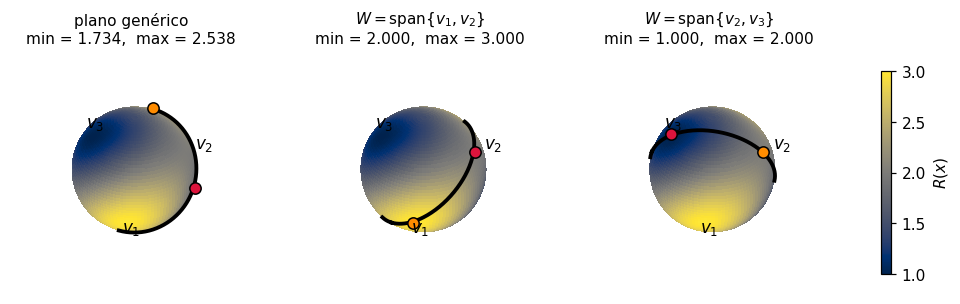

In [124]:
# Esfera colorida por R(x) = x^T A3 x, com um grande círculo W ∩ S e seus extremos.
_u, _v = np.meshgrid(np.linspace(0, 2 * np.pi, 120), np.linspace(0, np.pi, 60))
ESF = np.stack([np.cos(_u) * np.sin(_v), np.sin(_u) * np.sin(_v), np.cos(_v)], axis=-1)
R_ESF = np.einsum("...i,ij,...j->...", ESF, A3, ESF)

def base_do_plano(nrm):
    nrm = nrm / np.linalg.norm(nrm)
    t = np.array([1.0, 0, 0]) if abs(nrm[0]) < 0.9 else np.array([0, 1.0, 0])
    a = t - (t @ nrm) * nrm; a /= np.linalg.norm(a)
    return np.column_stack([a, np.cross(nrm, a)])

def extremos_no_circulo(nrm):
    # min e max de R em W ∩ S: são os autovalores da compressão 2x2 (Teorema 2 aplicado em W).
    Bw = base_do_plano(nrm)
    mu, Y = np.linalg.eigh(Bw.T @ A3 @ Bw)
    return mu[0], Bw @ Y[:, 0], mu[1], Bw @ Y[:, 1]

def normal_de(phi_graus, theta_graus):
    p, t = np.radians(phi_graus), np.radians(theta_graus)
    return np.array([np.sin(p) * np.cos(t), np.sin(p) * np.sin(t), np.cos(p)])

# Ponto de vista: olhamos a esfera de modo que v_1, v_2, v_3 fiquem no hemisfério da frente.
_e = (v1 + v2 + v3) / np.linalg.norm(v1 + v2 + v3)
ELEV, AZIM = np.degrees(np.arcsin(_e[2])), np.degrees(np.arctan2(_e[1], _e[0]))
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
ESCALA = ScalarMappable(norm=Normalize(1, 3), cmap="cividis")

def so_frente(P):
    # Esconde (com NaN) os pontos do hemisfério de trás.
    P = np.array(P, float)
    P[P @ _e < 0] = np.nan
    return P

def eixo_esfera(fig, *pos):
    ax = fig.add_subplot(*pos, projection="3d", computed_zorder=False)
    ax.view_init(elev=ELEV, azim=AZIM)
    ax.set_box_aspect((1, 1, 1)); ax.set_axis_off()
    return ax

def desenhar(ax, nrm, titulo=None):
    ax.plot_surface(*np.moveaxis(ESF, -1, 0), facecolors=ESCALA.to_rgba(R_ESF), rstride=1, cstride=1,
                    linewidth=0, antialiased=False, shade=False, zorder=1)
    Bw = base_do_plano(nrm)
    s = np.linspace(0, 2 * np.pi, 400)
    C = 1.01 * (np.outer(np.cos(s), Bw[:, 0]) + np.outer(np.sin(s), Bw[:, 1]))
    ax.plot(*so_frente(C).T, color="black", lw=2.5, zorder=5)
    mn, pmn, mx, pmx = extremos_no_circulo(nrm)
    for sg in (1, -1):
        for p, cor in [(pmn, "crimson"), (pmx, "darkorange")]:
            if sg * p @ _e > 0:
                ax.scatter(*(1.03 * sg * p), color=cor, edgecolor="black", s=55, depthshade=False, zorder=6)
    for w, nome in [(v1, "$v_1$"), (v2, "$v_2$"), (v3, "$v_3$")]:
        ax.text(*(1.22 * w), nome, fontsize=11, zorder=7)
    ax.set_title(titulo or f"min = {mn:.3f},  max = {mx:.3f}", fontsize=10)

fig = plt.figure(figsize=(12, 4.0))
for i, (nrm, nome) in enumerate([(normal_de(50, 30), "plano genérico"),
                                 (v3, r"$W=\mathrm{span}\{v_1,v_2\}$"),
                                 (v1, r"$W=\mathrm{span}\{v_2,v_3\}$")]):
    ax = eixo_esfera(fig, 1, 3, i + 1)
    mn, _, mx, _ = extremos_no_circulo(nrm)
    desenhar(ax, nrm, f"{nome}\nmin = {mn:.3f},  max = {mx:.3f}")
fig.colorbar(ESCALA, ax=fig.axes, shrink=0.6, label=r"$R(x)$")
plt.show()

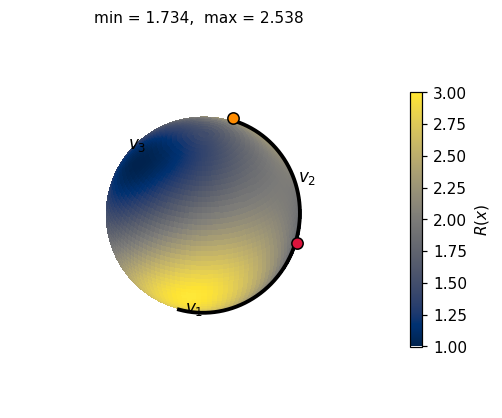

interactive(children=(FloatSlider(value=50.0, description='φ (graus)', max=180.0, step=2.0), FloatSlider(value…

In [129]:
# Versão interativa (Colab / JupyterLab). Sem ipywidgets, desenha um exemplo fixo.
def explorar(phi=50.0, theta=30.0):
    fig = plt.figure(figsize=(5.5, 5))
    desenhar(eixo_esfera(fig, 1, 1, 1), normal_de(phi, theta))
    fig.colorbar(ESCALA, ax=fig.axes, shrink=0.6, label=r"$R(x)$")
    plt.show()

try:
    from ipywidgets import interact, FloatSlider
    interact(explorar,
             phi=FloatSlider(min=0, max=180, step=2, value=50, description="φ (graus)"),
             theta=FloatSlider(min=0, max=360, step=2, value=30, description="ϑ (graus)"))
except ImportError:
    explorar()

## 8. Demonstração

A essência da demonstração é um argumento de contagem de dimensões.

**Lema 6 (interseção de subespaços).** Se $W_1,W_2\subset U$ com $\dim(W_1+W_2) \le n$ e $\dim W_1+\dim W_2>n$. então $W_1\cap W_2\neq\{0\}$.

*Demonstração.* Pela fórmula da dimensão da soma de subspaços, $\dim(W_1\cap W_2)=\dim W_1+\dim W_2-\dim(W_1+W_2)\ge\dim W_1+\dim W_2-n>0$. $\square$

*Demonstração do Teorema 4.* Seja $v_1,\dots,v_n$ uma base ortonormal de autovetores, $Av_i=\lambda_iv_i$ (Teorema 3). Usaremos repetidamente o corolário do §4: $R_A(x)$ é uma média ponderada dos $\lambda_i$, com pesos $t_i\propto|c_i|^2$ onde $x=\sum_ic_iv_i$.

**Primeira igualdade, "$\ge$".** Tome $W_\star=\operatorname{span}\{v_1,\dots,v_k\}$, de dimensão $k$. Para $x\in W_\star\setminus\{0\}$, só $c_1,\dots,c_k$ podem ser não nulos, então $R_A(x)$ é média ponderada de $\lambda_1,\dots,\lambda_k$, todos $\ge\lambda_k$. Logo $\min_{W_\star}R_A\ge\lambda_k$ (com igualdade em $x=v_k$), e portanto
$$\max_{\dim W=k}\ \min_WR_A\ \ge\ \min_{W_\star}R_A\ =\ \lambda_k .$$

**Primeira igualdade, "$\le$".** Seja $W$ **qualquer** subespaço de dimensão $k$, e seja $V=\operatorname{span}\{v_k,\dots,v_n\}$, de dimensão $n-k+1$. Como $k+(n-k+1)=n+1>n$, o Lema 6 dá $x\neq0$ em $W\cap V$. Para esse $x$, $R_A(x)$ é média ponderada de $\lambda_k,\dots,\lambda_n$, todos $\le\lambda_k$; logo
$$\min_WR_A\le R_A(x)\le\lambda_k .$$
Como $W$ era arbitrário, $\max_{\dim W=k}\min_WR_A\le\lambda_k$. Juntando, vale a igualdade, e o máximo é atingido em $W_\star$.

**Segunda igualdade.** Aplique a primeira a $-A$, que é autoadjunto com autovalores $-\lambda_n\ge\cdots\ge-\lambda_1$; o $j$-ésimo maior é $-\lambda_{n-j+1}$. Como $R_{-A}=-R_A$,
$$-\lambda_{n-j+1}=\max_{\dim W=j}\ \min_W(-R_A)=-\min_{\dim W=j}\ \max_WR_A .$$
Com $j=n-k+1$, isto é exatamente $\lambda_k=\min_{\dim W=n-k+1}\max_WR_A$. $\blacksquare$

**Resumo da ideia.** Um subespaço de dimensão $k$ é "grande demais" para fugir de $\operatorname{span}\{v_k,\dots,v_n\}$, onde $R_A\le\lambda_k$. Por isso nenhum $W$ consegue ter mínimo acima de $\lambda_k$ — e o melhor $W$ atinge exatamente $\lambda_k$.

### Verificação numérica

Para um $W$ com base ortonormal $Q$ (matriz $n\times k$), $R_A(Qy)=\dfrac{y^*(Q^*AQ)y}{y^*y}$: o quociente de Rayleigh de $A$ restrito a $W$ é o quociente de Rayleigh da **compressão** $Q^*AQ$, uma matriz $k\times k$ hermitiana. Pelo Teorema 2, $\min_WR_A=\lambda_{\min}(Q^*AQ)$. Abaixo sorteamos milhares de subespaços $W$ e verificamos que o mínimo nunca passa de $\lambda_k$, que o máximo de cada subespaço de dimensão $n-k+1$ nunca fica abaixo de $\lambda_k$, e que $W_\star$ atinge o valor exato.

lambda_3 = 2.0
max dos mínimos sorteados (dim W = 3)       = 1.8764   (nunca > lambda_k)
min dos máximos sorteados (dim W = 4)       = 2.0049   (nunca < lambda_k)
min de R em W* = span(v_1..v_3)            = 2.0000
max de R em span(v_3..v_6)               = 2.0000


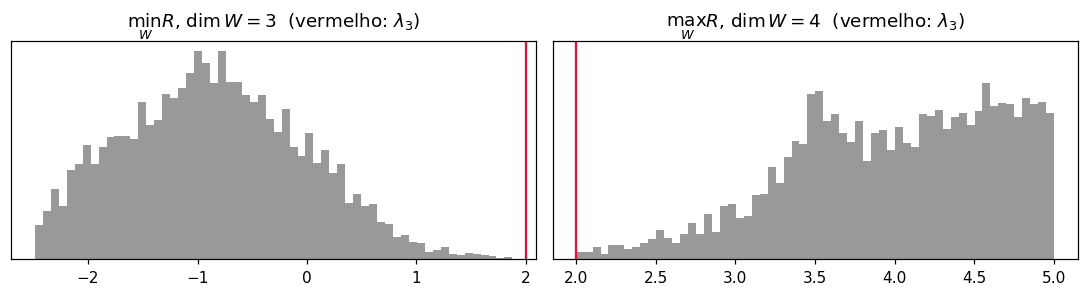

In [178]:
n, k = 6, 3
lam_ord = np.array([5.0, 3.5, 2.0, 0.5, -1.0, -2.5])
A = com_autovalores(lam_ord)
_, V = np.linalg.eigh(A); V = V[:, ::-1]          # colunas v_1, ..., v_n (ordem decrescente)

def subespaco_aleatorio(dim):
    Q, _ = np.linalg.qr(rng.standard_normal((n, dim)))
    return Q

mins = np.array([np.linalg.eigvalsh((Q := subespaco_aleatorio(k)).T @ A @ Q)[0] for _ in range(5000)])
maxs = np.array([np.linalg.eigvalsh((Q := subespaco_aleatorio(n - k + 1)).T @ A @ Q)[-1] for _ in range(5000)])
W_star, W_star2 = V[:, :k], V[:, k - 1:]

print(f"lambda_{k} = {lam_ord[k-1]}")
print(f"max dos mínimos sorteados (dim W = {k})       = {mins.max():.4f}   (nunca > lambda_k)")
print(f"min dos máximos sorteados (dim W = {n-k+1})       = {maxs.min():.4f}   (nunca < lambda_k)")
print(f"min de R em W* = span(v_1..v_{k})            = {np.linalg.eigvalsh(W_star.T @ A @ W_star)[0]:.4f}")
print(f"max de R em span(v_{k}..v_{n})               = {np.linalg.eigvalsh(W_star2.T @ A @ W_star2)[-1]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 2.8), sharey=True)
ax[0].hist(mins, bins=60, color="0.6"); ax[0].axvline(lam_ord[k-1], color="crimson")
ax[0].set_title(rf"$\min_W R$, $\dim W={k}$  (vermelho: $\lambda_{k}$)")
ax[1].hist(maxs, bins=60, color="0.6"); ax[1].axvline(lam_ord[k-1], color="crimson")
ax[1].set_title(rf"$\max_W R$, $\dim W={n-k+1}$  (vermelho: $\lambda_{k}$)")
for a in ax: a.set_yticks([])
plt.tight_layout(); plt.show()

---
## 10. Exercícios

Tente cada um antes de abrir a solução.

**Exercício 1 (onde entra a autoadjunção).** Seja $A=\begin{pmatrix}0&1\\0&0\end{pmatrix}$ em $\mathbb{R}^2$. Calcule $\max_SF_A$ e os autovalores de $A$. Qual passo da Parte I falha, e o que o cálculo de Lagrange encontra no lugar dos autovetores de $A$?

<details><summary><b>Solução</b></summary>

$F_A(x)=x_1x_2$, cujo máximo em $S$ é $\tfrac12$, em $x=\tfrac1{\sqrt2}(1,1)$; mas o único autovalor de $A$ é $0$. O Teorema 1 continua valendo (existe máximo), o que falha é o §3: sem simetria, $\partial f/\partial x_k=\sum_ja_{kj}x_j+\sum_ix_ia_{ik}=\bigl((A+A^{\mathsf T})x\bigr)_k$, e a condição de Lagrange vira $\tfrac12(A+A^{\mathsf T})v=\mu v$. Ou seja, Lagrange encontra os autovetores da **parte simétrica** $\tfrac12(A+A^{\mathsf T})=\begin{pmatrix}0&1/2\\1/2&0\end{pmatrix}$, cujos autovalores são $\pm\tfrac12$. Em geral $F_A=F_{(A+A^{\mathsf T})/2}$: a forma quadrática não "enxerga" a parte antissimétrica.
</details>


**Exercício 2 (variantes da deflação).** (a) Na Parte I extraímos máximo **e** mínimo a cada passo. Reescreva o algoritmo usando só o máximo. O que muda no número de passos e na ordenação? (b) ⋆ Suponha $\lambda_k>\lambda_{k+1}$ e seja $W$ um subespaço de dimensão $k$ que atinge o máximo na primeira fórmula de Courant–Fischer, isto é, $\min_WR_A=\lambda_k$. Mostre que $v_k\in W$.

<details><summary><b>Solução</b></summary>

(a) Cada passo produz um autovetor; são $n$ passos, e os autovalores saem diretamente em ordem decrescente, pela monotonia $M_{k+1}\le M_k$. O argumento é o mesmo.

(b) Como na demonstração, existe $x\neq0$ em $W\cap\operatorname{span}\{v_k,\dots,v_n\}$. Escreva $x=c_kv_k+z$ com $z\in\operatorname{span}\{v_{k+1},\dots,v_n\}$. Então
$$R_A(x)=\frac{\lambda_k|c_k|^2+\sum_{i>k}\lambda_i|c_i|^2}{|c_k|^2+\|z\|^2}\le\frac{\lambda_k|c_k|^2+\lambda_{k+1}\|z\|^2}{|c_k|^2+\|z\|^2},$$
que é $<\lambda_k$ se $z\neq0$ (pois $\lambda_{k+1}<\lambda_k$). Mas $R_A(x)\ge\min_WR_A=\lambda_k$; logo $z=0$, isto é, $x$ é múltiplo não nulo de $v_k$, e $v_k\in W$.</details>

---
## Resumo

* Para $A$ autoadjunto, $F_A(x)=\langle x,Ax\rangle$ é real e contínua, e $S$ é compacta (dimensão finita + completude): $F_A$ atinge seu máximo e mínimo em $S$.
* Por Lagrange, os pontos críticos de $F_A$ em $S$ são os autovetores normalizados, e o multiplicador é o autovalor: $\max_SF_A=\lambda_1$, $\min_SF_A=\lambda_n$.
* Autoadjunção torna $H^\perp$ invariante quando $H$ é gerado por autovetores; restringindo e repetindo (deflação), obtém-se uma base ortonormal de autovetores — o **teorema espectral** — com os autovalores já ordenados.
* $R_A(x)$ é uma média ponderada dos autovalores com pesos $|c_i|^2$.
* **Courant–Fischer:** $\lambda_k=\max_{\dim W=k}\min_WR_A=\min_{\dim W=n-k+1}\max_WR_A$, sem referência a autovetores. A prova é uma contagem de dimensões.


**Referências.** R. Horn e C. Johnson, *Matrix Analysis*, cap. 4 (Rayleigh, Courant–Fischer, Weyl, entrelaçamento). P. Lax, *Linear Algebra and Its Applications*, cap. 8 (teoria espectral de operadores autoadjuntos, com a abordagem variacional).